
# Building Energy Efficiency Prediction

## Topic: Data Understanding and Exploratory Data Analysis

**Author:** Abubakar Abubakar Qasim

**Date:** 27 October 2026

### Objective

The objective of this notebook is to understand the
structure, quality, and characteristics of the
Building Energy Efficiency dataset and explore how
architectural features relate to heating and cooling loads.

### Tasks

- Import required libraries
- Load the dataset
- Inspect the dataset structure
- Understand the input features and target variables
- Check missing values and duplicate records
- Generate descriptive statistics
- Visualise feature and target distributions
- Perform correlation analysis
- Document observations and key findings


In [20]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)
pd.set_option("display.float_format", "{:.3f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [21]:

# Load the Energy Efficiency dataset

df = pd.read_excel("../data/ENB2012_data.xlsx")

print(f"Dataset loaded successfully: {df.shape}")

df.head()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()



Dataset loaded successfully: (768, 10)

Column Names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [22]:

# Check for missing values

print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate records

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Missing Values:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64

Number of Duplicate Rows:
0


In [23]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
X1,768.000,0.764,0.106,0.620,0.682,0.750,0.830,0.980
X2,768.000,671.708,88.086,514.500,606.375,673.750,741.125,808.500
X3,768.000,318.500,43.626,245.000,294.000,318.500,343.000,416.500
X4,768.000,176.604,45.166,110.250,140.875,183.750,220.500,220.500
X5,768.000,5.250,1.751,3.500,3.500,5.250,7.000,7.000
X6,768.000,3.500,1.119,2.000,2.750,3.500,4.250,5.000
X7,768.000,0.234,0.133,0.000,0.100,0.250,0.400,0.400
X8,768.000,2.812,1.551,0.000,1.750,3.000,4.000,5.000
Y1,768.000,22.307,10.090,6.010,12.992,18.950,31.668,43.100
Y2,768.000,24.588,9.513,10.900,15.620,22.080,33.133,48.030




## Renaming Dataset Columns

I identified that the original dataset uses generic
column names (X1–X8 and Y1–Y2).

I renamed these columns to improve readability and
make my exploratory analysis easier to understand.



In [24]:

# Rename the dataset columns

df.rename(columns={
    "X1": "Relative_Compactness",
    "X2": "Surface_Area",
    "X3": "Wall_Area",
    "X4": "Roof_Area",
    "X5": "Overall_Height",
    "X6": "Orientation",
    "X7": "Glazing_Area",
    "X8": "Glazing_Area_Distribution",
    "Y1": "Heating_Load",
    "Y2": "Cooling_Load"
}, inplace=True)

# Display the first five rows
display(df.head())


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.980,514.500,294.000,110.250,7.000,2,0.000,0,15.550,21.330
1,0.980,514.500,294.000,110.250,7.000,3,0.000,0,15.550,21.330
2,0.980,514.500,294.000,110.250,7.000,4,0.000,0,15.550,21.330
3,0.980,514.500,294.000,110.250,7.000,5,0.000,0,15.550,21.330
4,0.900,563.500,318.500,122.500,7.000,2,0.000,0,20.840,28.280


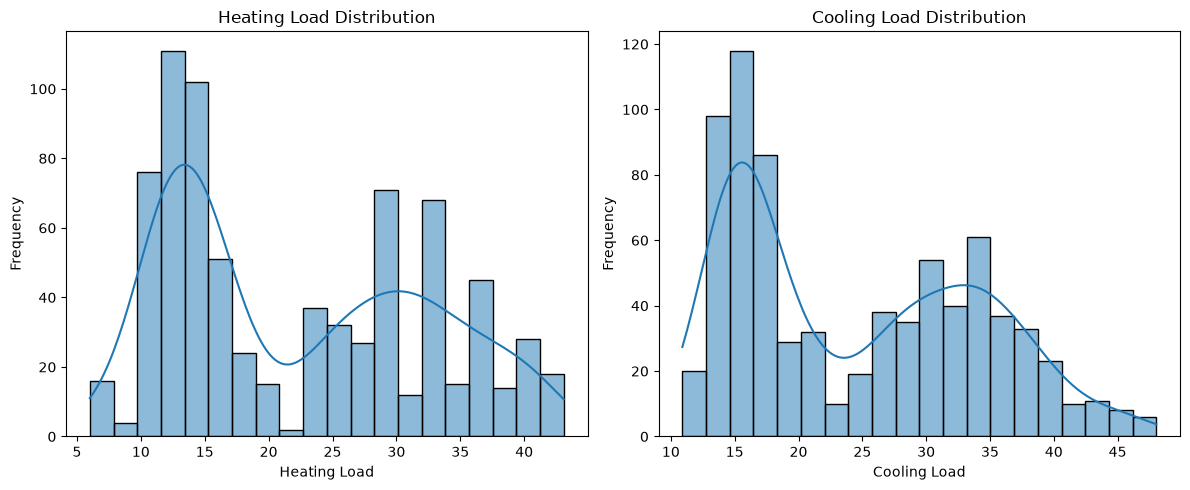

In [25]:

# Visualise heating and cooling load distributions

plt.figure(figsize=(12, 5))

# Heating Load distribution
plt.subplot(1, 2, 1)
sns.histplot(df["Heating_Load"], bins=20, kde=True)
plt.title("Heating Load Distribution")
plt.xlabel("Heating Load")
plt.ylabel("Frequency")

# Cooling Load distribution
plt.subplot(1, 2, 2)
sns.histplot(df["Cooling_Load"], bins=20, kde=True)
plt.title("Cooling Load Distribution")
plt.xlabel("Cooling Load")
plt.ylabel("Frequency")

# Adjust spacing and display
plt.tight_layout()
plt.show()



### Observations

- Both heating and cooling loads exhibit bimodal distributions,
  indicating two main concentrations of energy-load values.

- Heating loads are concentrated around 11–16 and 25–36.

- Cooling loads are concentrated around 14–19 and 28–38.

- Cooling load values extend somewhat higher than heating loads.

- The observed patterns may be associated with differences in
  building characteristics such as surface area, overall height,
  and glazing area.

- Further analysis is required to determine which architectural
  features are most strongly associated with energy requirements.


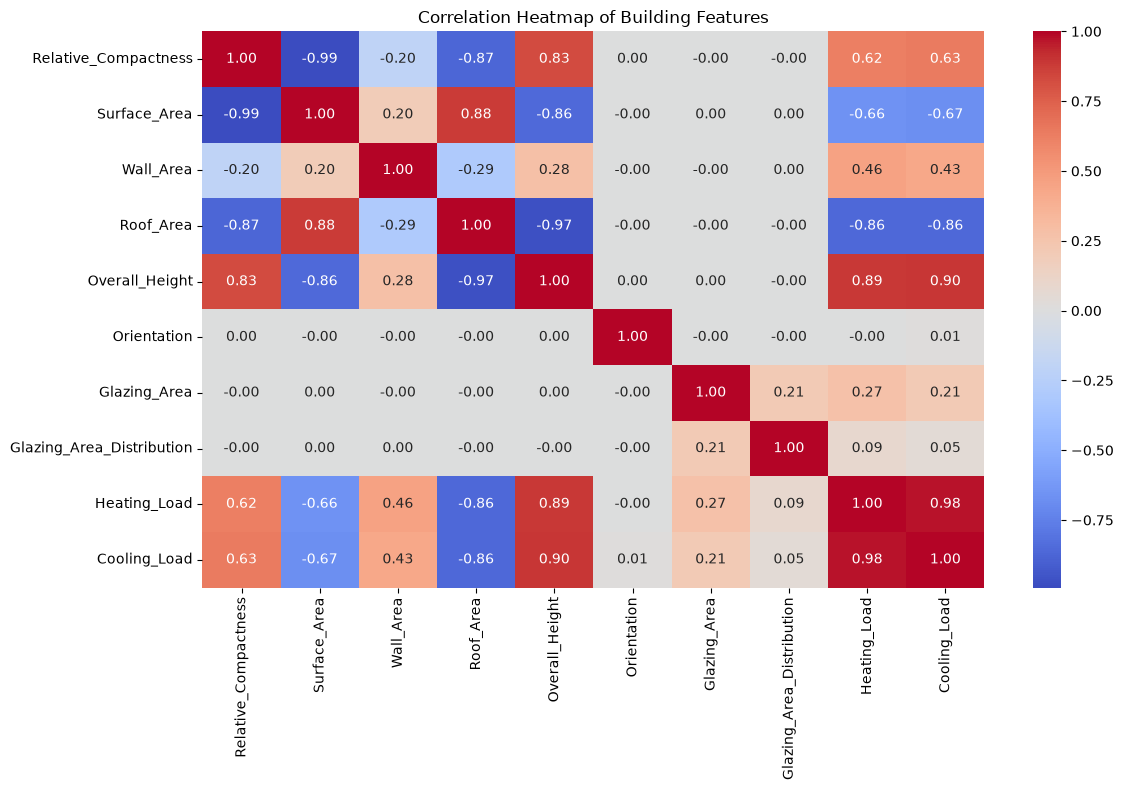

In [26]:

# Calculate the correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Create the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Building Features")
plt.tight_layout()
plt.show()



### Correlation Analysis — Key Findings

- Overall Height has strong positive correlations with
  Heating Load (0.89) and Cooling Load (0.90).

- Roof Area shows strong negative correlations with
  both Heating Load and Cooling Load (-0.86).

- Relative Compactness shows moderately strong
  positive correlations with both target variables.

- Heating Load and Cooling Load are highly correlated
  (0.98), indicating similar patterns across buildings.

- Strong correlations exist between some input features,
  suggesting possible multicollinearity.

- Correlation does not establish causation. Further
  analysis and machine learning modelling are required.

- Orientation and Glazing Area Distribution are coded
  categorical features, so their Pearson correlations
  should be interpreted cautiously.


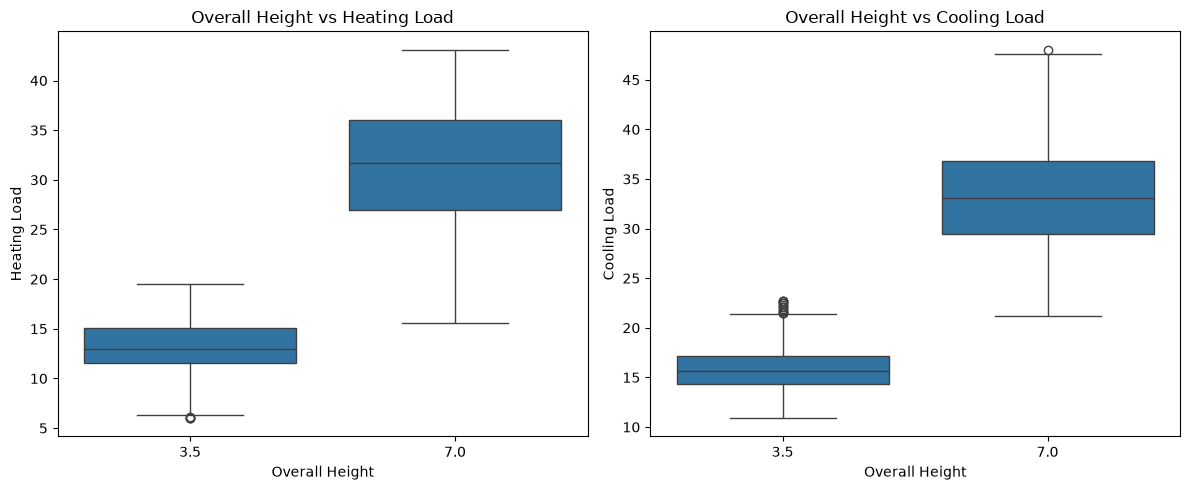

In [27]:
# Analyse the relationship between building height and energy loads

plt.figure(figsize=(12, 5))

# Overall height vs Heating load 
plt.subplot(1, 2, 1)
sns.boxplot(x="Overall_Height", y="Heating_Load", data=df)
plt.title("Overall Height vs Heating Load")
plt.xlabel("Overall Height")
plt.ylabel("Heating Load")

# Overall Height vs Cooling Load
plt.subplot(1, 2, 2)
sns.boxplot(x="Overall_Height", y="Cooling_Load", data=df)
plt.title("Overall Height vs Cooling Load")
plt.xlabel("Overall Height")
plt.ylabel("Cooling Load")

plt.tight_layout()
plt.show()



### Observations

- The dataset contains two overall height values: 3.5 and 7.0.

- Buildings with an overall height of 7.0 generally
  have higher heating and cooling loads.

- Buildings with an overall height of 3.5 have lower
  median heating and cooling requirements.

- The taller building group shows greater variation
  in energy loads.

- Some potential outliers are observed in the
  shorter building group.

- These findings support the strong positive
  correlations observed in the correlation heatmap.

- However, the relationship does not establish
  that building height alone causes higher loads.


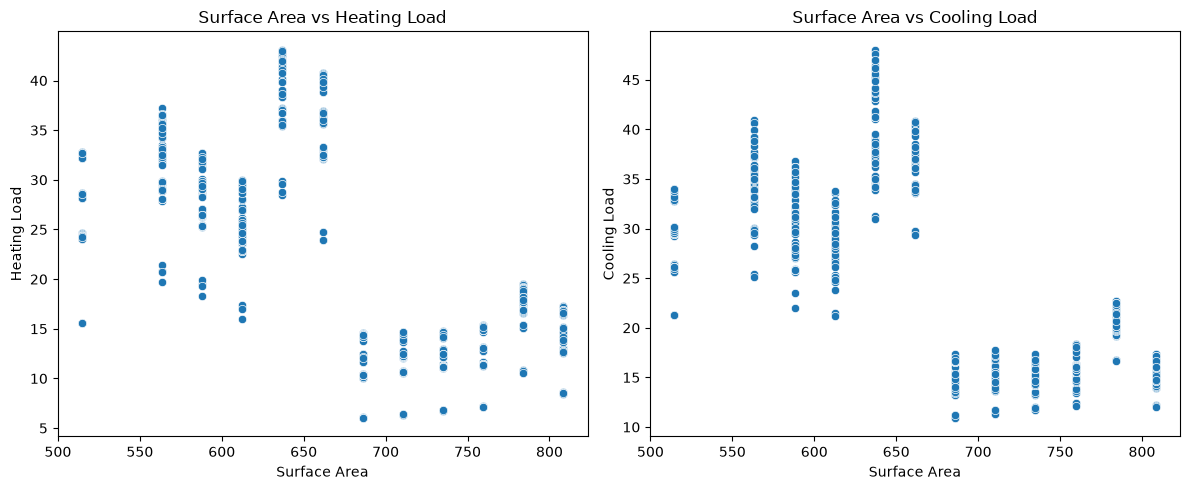

In [28]:
# Visualise Surface Area vs Heating and Cooling Loads

plt.figure(figsize=(12, 5))

# Surface Area vs Heating Load
plt.subplot(1, 2, 1)
sns.scatterplot(x="Surface_Area", y="Heating_Load", data=df)
plt.title("Surface Area vs Heating Load")
plt.xlabel("Surface Area")
plt.ylabel("Heating Load")

# Surface Area vs Cooling Load
plt.subplot(1, 2, 2)
sns.scatterplot(x="Surface_Area", y="Cooling_Load", data=df)
plt.title("Surface Area vs Cooling Load")
plt.xlabel("Surface Area")
plt.ylabel("Cooling Load")

plt.tight_layout()
plt.show()




### Observations

- Surface Area shows an overall negative relationship with
  both Heating Load and Cooling Load.

- Building configurations with smaller surface areas
  generally exhibit higher heating and cooling loads.

- Larger surface-area configurations generally show
  lower energy requirements in this dataset.

- The vertical groups indicate repeated surface-area
  values across different building configurations.

- The relationships are not perfectly linear, suggesting
  that other architectural characteristics may contribute
  to variations in energy loads.

- These observations support the negative correlations
  identified in the correlation heatmap.

- Correlation does not establish that increasing surface
  area independently reduces energy requirements.


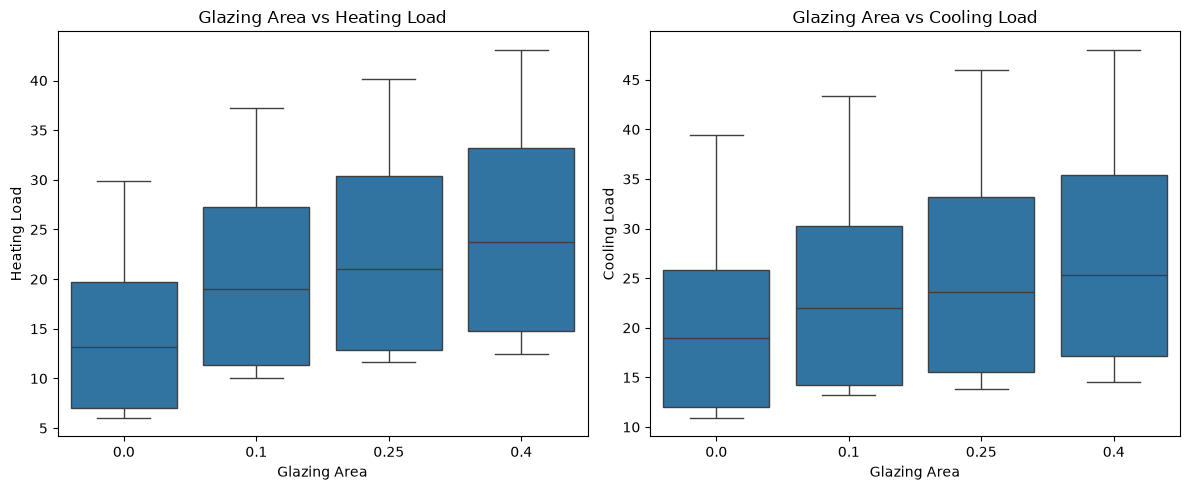

In [29]:

# Visualise Glazing Area vs Heating and Cooling Loads

plt.figure(figsize=(12, 5))

# Glazing Area vs Heating Load
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="Glazing_Area", y="Heating_Load")
plt.title("Glazing Area vs Heating Load")
plt.xlabel("Glazing Area")
plt.ylabel("Heating Load")

# Glazing Area vs Cooling Load
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="Glazing_Area", y="Cooling_Load")
plt.title("Glazing Area vs Cooling Load")
plt.xlabel("Glazing Area")
plt.ylabel("Cooling Load")

plt.tight_layout()
plt.show()



### Observations

- The dataset contains four glazing-area values:
  0.0, 0.1, 0.25, and 0.4.

- Median heating and cooling loads generally increase
  as glazing area increases.

- Buildings with larger glazing areas tend to show
  greater variation in energy requirements.

- The observed patterns support the weak positive
  correlations identified in the correlation heatmap.

- These relationships do not establish causation,
  since other building characteristics may influence
  heating and cooling requirements.




## Saving the Dataset

After examining the dataset and completing my exploratory
data analysis, I renamed the columns to improve readability.

I will save the dataset in CSV format so I can use it
in the next notebook without repeating the column-renaming
process.

I will perform further data preprocessing and feature
preparation in Notebook 02.



In [30]:

# Save the dataset with renamed columns

df.to_csv("../data/energy_efficiency_renamed.csv", index=False)

print("Dataset saved successfully!")
print("Dataset Shape:", df.shape)


Dataset saved successfully!
Dataset Shape: (768, 10)



## Summary and Key Findings

In this notebook, I explored the UCI Energy Efficiency
dataset to understand how building characteristics relate
to heating and cooling requirements.

### Key Findings

1. **Dataset Overview**
   - I loaded a dataset containing 768 observations,
     8 input features, and 2 target variables.
   - I examined the dataset structure, descriptive
     statistics, and data quality.

2. **Heating and Cooling Load Distributions**
   - I observed bimodal distributions for both heating
     and cooling loads, indicating two main groups
     of energy requirements.

3. **Correlation Analysis**
   - I identified strong positive correlations between
     Overall Height and Heating Load (0.89) and
     Cooling Load (0.90).
   - Roof Area showed strong negative correlations
     with both target variables (-0.86).
   - Heating Load and Cooling Load were strongly
     correlated (0.98).

4. **Building Height**
   - I observed that taller building configurations
     generally have higher heating and cooling loads.

5. **Surface Area**
   - I identified an overall negative relationship
     between Surface Area and both energy loads.

6. **Glazing Area**
   - I observed that median heating and cooling loads
     generally increase with glazing area.

### Conclusion

My exploratory analysis revealed important relationships
between architectural characteristics and building energy
requirements.

However, these relationships do not establish causation.

In the next notebook, I will prepare the dataset, split
the features and targets, and develop regression models
to predict heating and cooling loads.
